Lab 1 — Build Your First Image Encoder–Decoder
Name: Anant Arya
Roll number: A24ARIU0014

This notebook builds a small convolutional autoencoder for MNIST.

In [1]:
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 64
EPOCHS = 5
LATENT_CHANNELS = 8
print("Device:", device)

Device: cpu


100%|██████████| 9.91M/9.91M [00:01<00:00, 6.06MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 162kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.52MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.19MB/s]


Batch: (64, 1, 28, 28) Pixel range: 0.0 1.0


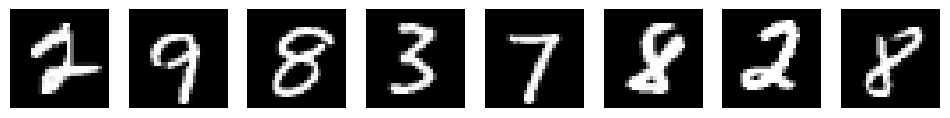

In [2]:
# ToTensor converts grayscale pixels to the [0, 1] range.
train_data = datasets.MNIST("./data", train=True, download=True, transform=transforms.ToTensor())
test_data = datasets.MNIST("./data", train=False, download=True, transform=transforms.ToTensor())
# Small, fixed subsets make this lab faster and repeatable.
g = torch.Generator().manual_seed(42)
train_data = Subset(train_data, torch.randperm(len(train_data), generator=g)[:5000].tolist())
test_data = Subset(test_data, torch.randperm(len(test_data), generator=g)[:1000].tolist())
train_loader = DataLoader(train_data, batch_size=64, shuffle=True, num_workers=0)
test_loader = DataLoader(test_data, batch_size=64, shuffle=False, num_workers=0)
images, labels = next(iter(train_loader))
print("Batch:", tuple(images.shape), "Pixel range:", images.min().item(), images.max().item())
fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for ax, image in zip(axes, images[:8]):
    ax.imshow(image[0], cmap="gray", vmin=0, vmax=1); ax.axis("off")
plt.show()

2. Shape predictions and bottleneck math
For a convolution, the spatial output is floor((H + 2P - D(K-1) - 1)/S + 1). Here both 3×3 stride-2 convolutions map 28→14→7. The 1×1 bottleneck keeps the 7×7 grid.
Stage	Output shape
Input	[N, 1, 28, 28]
Encoder 1	[N, 16, 14, 14]
Encoder 2	[N, 32, 7, 7]
Bottleneck (L=8)	[N, 8, 7, 7]
Decoder 1	[N, 16, 14, 14]
Decoder 2	[N, 1, 28, 28]


- Input values per image: 1 × 28 × 28 = 784.
- With L=8, latent values: 8 × 7 × 7 = 392; input/latent ratio: 784 / 392 = 2.
- With L=32, latent values are 32 × 7 × 7 = 1,568, so the latent is larger than the input (ratio 0.5) and is not dimensionally compressed.
- Sigmoid matches the [0, 1] pixel range produced by ToTensor().
- With output_padding=0, the first transposed convolution gives height (7−1)×2 − 2×1 + 3 + 0 = 13 pixels. output_padding=1 makes it 14.

In [3]:
class Encoder(nn.Module):
    def __init__(self, latent_channels=8):
        super().__init__()
        self.network = nn.Sequential(
            # [N, 1, 28, 28] -> [N, 16, 14, 14]
            nn.Conv2d(1, 16, kernel_size=3, stride=2, padding=1), nn.ReLU(),
            # [N, 16, 14, 14] -> [N, 32, 7, 7]
            nn.Conv2d(16, 32, kernel_size=3, stride=2, padding=1), nn.ReLU(),
            # Mix channels at each location and keep the 7x7 grid.
            nn.Conv2d(32, latent_channels, kernel_size=1)
        )
    def forward(self, x):
        return self.network(x)

class Decoder(nn.Module):
    def __init__(self, latent_channels=8):
        super().__init__()
        self.network = nn.Sequential(
            # [N, L, 7, 7] -> [N, 16, 14, 14]
            nn.ConvTranspose2d(latent_channels, 16, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.ReLU(),
            # [N, 16, 14, 14] -> [N, 1, 28, 28]
            nn.ConvTranspose2d(16, 1, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.Sigmoid()
        )
    def forward(self, z):
        return self.network(z)

class ImageEncoderDecoder(nn.Module):
    def __init__(self, latent_channels=8):
        super().__init__()
        self.encoder = Encoder(latent_channels)
        self.decoder = Decoder(latent_channels)
    def forward(self, x):
        z = self.encoder(x)
        reconstruction = self.decoder(z)
        return reconstruction, z

In [4]:
# Shape and value-range checks
model = ImageEncoderDecoder(LATENT_CHANNELS).to(device)
x = torch.rand(4, 1, 28, 28, device=device)
with torch.no_grad():
    reconstruction, z = model(x)
assert z.shape == (4, LATENT_CHANNELS, 7, 7)
assert reconstruction.shape == x.shape
assert torch.isfinite(reconstruction).all()
assert ((reconstruction >= 0) & (reconstruction <= 1)).all()
print("Input:", tuple(x.shape), "Latent:", tuple(z.shape), "Output:", tuple(reconstruction.shape))
print("Shape and range checks passed")

Input: (4, 1, 28, 28) Latent: (4, 8, 7, 7) Output: (4, 1, 28, 28)
Shape and range checks passed


4. Train with reconstruction loss
Mean squared error compares every output pixel with the corresponding input pixel. The optimizer updates both encoder and decoder parameters.

Untrained held-out MSE: 0.18629
Epoch 1: train MSE=0.11827, held-out MSE=0.04370
Epoch 2: train MSE=0.03428, held-out MSE=0.02552
Epoch 3: train MSE=0.01680, held-out MSE=0.00982
Epoch 4: train MSE=0.00826, held-out MSE=0.00614
Epoch 5: train MSE=0.00559, held-out MSE=0.00450


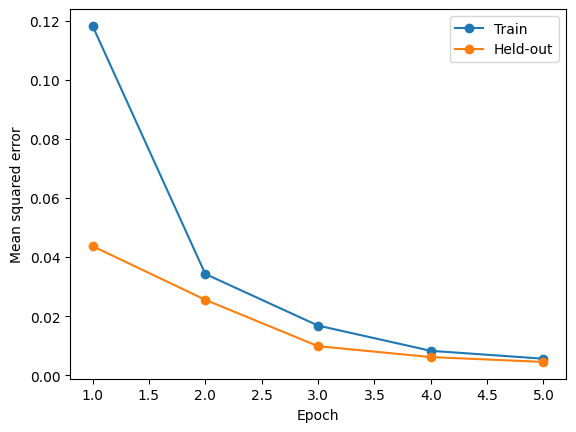

In [5]:
criterion = nn.MSELoss()

def train_step(model, images, optimizer, criterion):
    optimizer.zero_grad()                         # clear previous gradients
    reconstruction, _ = model(images)            # encode, then decode
    loss = criterion(reconstruction, images)      # input image is also target
    loss.backward()                               # calculate gradients
    optimizer.step()                              # update weights
    return loss.item()                            # Python number

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss = 0.0
    for images, _ in loader:
        images = images.to(device)
        reconstruction, _ = model(images)
        total_loss += criterion(reconstruction, images).item() * images.size(0)
    return total_loss / len(loader.dataset)

# Start with a fresh model and optimizer.
torch.manual_seed(42)
model = ImageEncoderDecoder(LATENT_CHANNELS).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
initial_mse = evaluate(model, test_loader)
print(f"Untrained held-out MSE: {initial_mse:.5f}")
history = {"train": [], "test": []}
for epoch in range(EPOCHS):
    model.train(); total_loss = 0.0
    for images, _ in train_loader:
        images = images.to(device)
        total_loss += train_step(model, images, optimizer, criterion) * images.size(0)
    history["train"].append(total_loss / len(train_loader.dataset))
    history["test"].append(evaluate(model, test_loader))
    print(f"Epoch {epoch + 1}: train MSE={history['train'][-1]:.5f}, held-out MSE={history['test'][-1]:.5f}")

plt.plot(range(1, EPOCHS + 1), history["train"], marker="o", label="Train")
plt.plot(range(1, EPOCHS + 1), history["test"], marker="o", label="Held-out")
plt.xlabel("Epoch"); plt.ylabel("Mean squared error"); plt.legend(); plt.show()

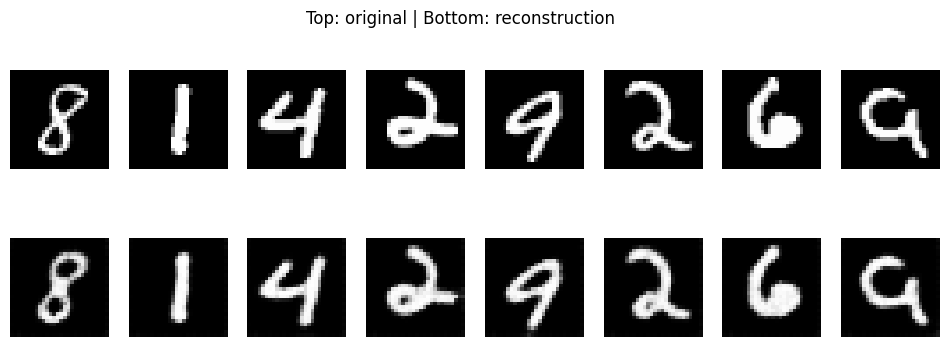

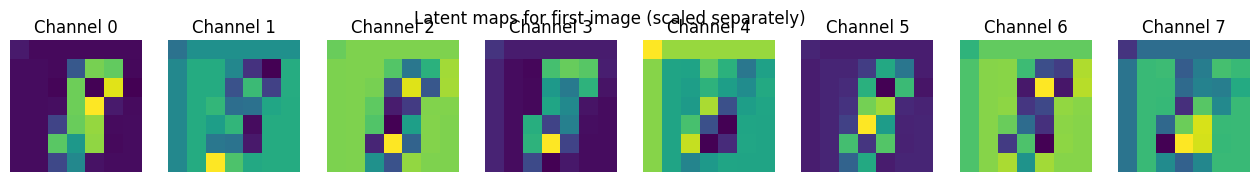

In [6]:
model.eval()
examples, _ = next(iter(test_loader))
with torch.no_grad():
    reconstructed, latents = model(examples[:8].to(device))
reconstructed, latents = reconstructed.cpu(), latents.cpu()
fig, axes = plt.subplots(2, 8, figsize=(12, 4))
for i in range(8):
    axes[0, i].imshow(examples[i, 0], cmap="gray", vmin=0, vmax=1)
    axes[1, i].imshow(reconstructed[i, 0], cmap="gray", vmin=0, vmax=1)
    axes[0, i].axis("off"); axes[1, i].axis("off")
fig.suptitle("Top: original | Bottom: reconstruction"); plt.show()
count = min(LATENT_CHANNELS, 8)
fig, axes = plt.subplots(1, count, figsize=(2 * count, 2), squeeze=False)
for i in range(count):
    axes[0, i].imshow(latents[0, i], cmap="viridis")
    axes[0, i].set_title(f"Channel {i}"); axes[0, i].axis("off")
fig.suptitle("Latent maps for first image (scaled separately)"); plt.show()

In [7]:
def run_experiment(latent_channels):
    torch.manual_seed(42)
    experiment_model = ImageEncoderDecoder(latent_channels).to(device)
    experiment_optimizer = torch.optim.Adam(experiment_model.parameters(), lr=1e-3)
    for epoch in range(EPOCHS):
        experiment_model.train()
        for batch_images, _ in train_loader:
            batch_images = batch_images.to(device)
            train_step(experiment_model, batch_images, experiment_optimizer, criterion)
    train_mse = evaluate(experiment_model, train_loader)
    test_mse = evaluate(experiment_model, test_loader)
    return train_mse, test_mse

results = []
for channels in (2, 8, 32):
    train_mse, test_mse = run_experiment(channels)
    latent_values = channels * 7 * 7
    results.append((channels, latent_values, 784 / latent_values, train_mse, test_mse))
print("L | latent values | input/latent | final train MSE | final held-out MSE")
for channels, values, ratio, train_mse, test_mse in results:
    print(f"{channels:2d} | {values:13d} | {ratio:11.2f} | {train_mse:15.5f} | {test_mse:18.5f}")

L | latent values | input/latent | final train MSE | final held-out MSE
 2 |            98 |        8.00 |         0.01134 |            0.01073
 8 |           392 |        2.00 |         0.00505 |            0.00466
32 |          1568 |        0.50 |         0.00333 |            0.00316


Optional extension: denoising
For denoising, feed noisy images into the model but keep the clean image as target. Use a fresh model and optimizer. Replace the model and loss lines in training with:

In [8]:
noisy = (images + 0.3 * torch.randn_like(images)).clamp(0, 1)
reconstruction, _ = model(noisy)
loss = criterion(reconstruction, images)